<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 21: Factor Analysis and Latent Factor Interpretation

**Category**: CO4 – Linear Factor Models and Probabilistic Graphical Models  
**Objective**: Extract and interpret orthogonal latent factors from high-dimensional survey ratings using maximum likelihood Factor Analysis.


### Task 1: Simulate Multi-Attribute Survey Data


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA

np.random.seed(123)
n_respondents = 350

# 2 Underlying latent traits: 1) Technical Skill, 2) Workplace Teamwork
f_tech = np.random.normal(0, 1, n_respondents)
f_team = np.random.normal(0, 1, n_respondents)

# 6 Observed survey ratings
q1_code = 0.85 * f_tech + np.random.normal(0, 0.25, n_respondents)
q2_debug = 0.80 * f_tech + np.random.normal(0, 0.30, n_respondents)
q3_arch = 0.75 * f_tech + np.random.normal(0, 0.35, n_respondents)

q4_collab = 0.82 * f_team + np.random.normal(0, 0.28, n_respondents)
q5_listen = 0.78 * f_team + np.random.normal(0, 0.32, n_respondents)
q6_empathy = 0.70 * f_team + np.random.normal(0, 0.40, n_respondents)

survey_df = pd.DataFrame({
    'Coding': q1_code, 'Debugging': q2_debug, 'Architecture': q3_arch,
    'Collaboration': q4_collab, 'Listening': q5_listen, 'Empathy': q6_empathy
})
print("Survey Assessment Items (First 5 Rows):\n", survey_df.head().round(2))


Survey Assessment Items (First 5 Rows):
    Coding  Debugging  Architecture  Collaboration  Listening  Empathy
0   -0.91      -1.17         -0.47          -0.29      -0.44    -0.60
1    0.61       0.87          0.85          -0.11      -0.16     0.14
2    0.64       0.34          0.48          -0.85      -0.81    -0.45
3   -1.19      -0.96         -0.97          -1.30      -0.56    -0.73
4   -0.55       0.13         -0.21          -1.28      -0.45    -0.87


### Task 2: Fit Factor Analysis and Extract Factor Loadings


In [2]:
fa = FactorAnalysis(n_components=2, random_state=42)
fa.fit(survey_df)

loadings = fa.components_.T # (6, 2)
df_loadings = pd.DataFrame(loadings, index=survey_df.columns, columns=['Factor 1 (Technical)', 'Factor 2 (Interpersonal)'])
print("Estimated Factor Loading Matrix:\n", df_loadings.round(3))


Estimated Factor Loading Matrix:
                Factor 1 (Technical)  Factor 2 (Interpersonal)
Coding                       -0.849                    -0.001
Debugging                    -0.789                    -0.012
Architecture                 -0.735                     0.010
Collaboration                -0.000                    -0.803
Listening                     0.010                    -0.751
Empathy                       0.003                    -0.709


### Task 3: Factor Loadings Heatmap and Latent Trait Biplot


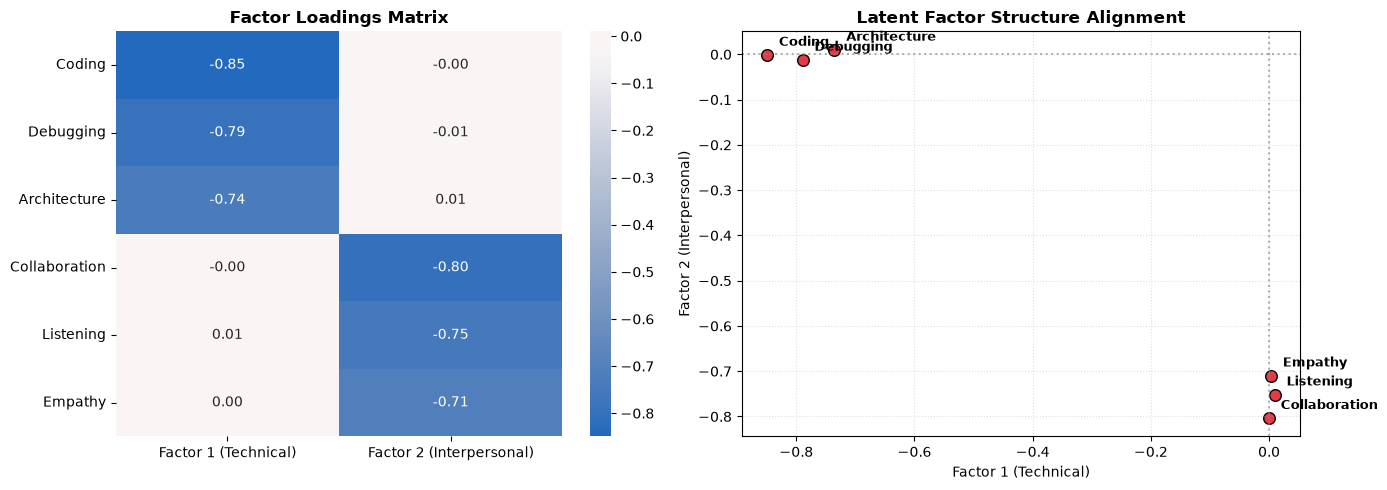

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Heatmap of factor loadings
sns.heatmap(df_loadings, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Factor Loadings Matrix", fontweight='bold')

# 2. Factor Biplot
axes[1].scatter(loadings[:, 0], loadings[:, 1], color='#e63946', s=70, edgecolors='k')
for i, txt in enumerate(survey_df.columns):
    axes[1].annotate(txt, (loadings[i, 0] + 0.02, loadings[i, 1] + 0.02), fontweight='bold', fontsize=9)
axes[1].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[1].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[1].set_title("Latent Factor Structure Alignment", fontweight='bold')
axes[1].set_xlabel("Factor 1 (Technical)")
axes[1].set_ylabel("Factor 2 (Interpersonal)")
axes[1].grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()
